
# Milestone 2: Honest Testing and Baselines to Beat

In this milestone, I use the MovieLens 100K dataset
to test different movie rating prediction methods.

I split the ratings into training and test sets,
build a few simple baseline models, and compare
their RMSE values to see which method works best.


## Part A: Load the MovieLens Ratings

   user  item  rating       time
0   196   242       3  881250949
1   186   302       3  891717742
2    22   377       1  878887116
3   244    51       2  880606923
4   166   346       1  886397596
Number of ratings: 100000
Number of users: 943
Number of movies: 1682



The dataset contains 100,000 movie ratings
from 943 users and 1,682 movies.

Each row contains a user ID, movie ID,
rating, and timestamp. I will use this
data to test how accurate different
rating prediction methods are.


## Part B: Train/Test Split

Train: 90032
Test: 9968
Test fraction: 0.1


... (9 outputs left out)

## Part F: User and Movie Effects

user + movie effects    0.9545
movie average           1.0284
user average            1.0426
overall average         1.1349
always 3                1.2516
Name: test RMSE, dtype: float64



This model combines the overall average rating
with both user and movie effects.

Some users give higher ratings than others,
and some movies are rated higher overall.

Combining both effects can give more accurate
predictions than using just one average.


## Comparing the Baseline Models

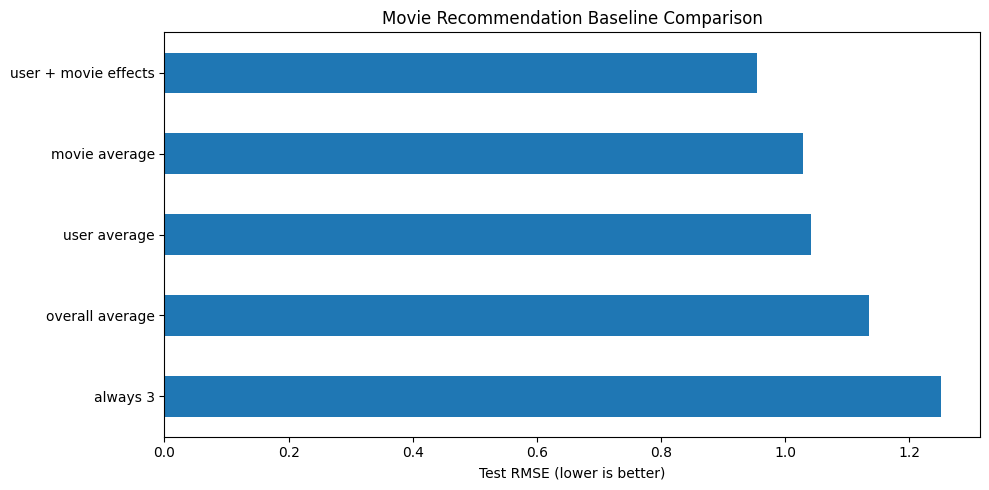


The graph compares the RMSE scores for all
five methods. The method with the lowest
RMSE makes the most accurate predictions
on the hidden ratings.

These results will be used as a baseline
for the SVD recommendation model later.


## Exercise 1: Tiny Ratings Matrix

Tiny matrix:
[[ 5.  3. nan]
 [ 4. nan  1.]
 [nan  2.  2.]]

Overall mean: 2.8333333333333335
User effects: [ 1.16666667 -0.33333333 -0.83333333]
Movie effects: [ 1.25 -0.5  -0.75]



### Hand Calculations

The seven known ratings are:

5, 3, 4, 1, 2, 2.

There are actually six known ratings.

The overall mean is:

$$
\mu=\frac{5+3+4+1+2+2}{6}
=\frac{17}{6}\approx2.8333
$$

The user effects are:

$$
b_{\text{user}}=
\left[
\frac{7}{6},
-\frac{1}{3},
-\frac{5}{6}
\right]
$$

The movie effects are:

$$
b_{\text{item}}=
\left[
\frac{1}{3},
-\frac{5}{6},
-\frac{1}{3}
\right]
$$

The computer calculation checks these values
using the same bias baseline function.


## Exercise 2: Data Leakage

Honest user-average RMSE: 1.0425731518955943
Cheating user-average RMSE: 1.0322056951414382
Cheating score lower? True


... (3 outputs left out)


The RMSE scores changed when I used a
different random seed because the training
and test ratings were different.

The ranking of the models
stayed the same.

This shows why recommendation models
should be compared using the same train
and test split. Testing with multiple
random seeds can also help show how
consistent the results are.


## Conclusion


In this milestone, I tested five different
movie rating prediction methods using RMSE.

The best model was **user + movie effects** with
an RMSE of **0.9545**.

I also tested what happens when hidden
ratings are used during training and
compared results using different random
seeds.

These baseline results will help me
compare the performance of the SVD model
in the next milestone.



Milestone 2 completed!
Created src/evaluate.py
Created src/models.py


In [1]:

# MATH 344L - Applied Linear Algebra Lab
# Project 2: A Movie Recommendation System
# Milestone 2: Honest Testing and Baselines to Beat

import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ============================================
# INTRODUCTION
# ============================================

display(Markdown("""
# Milestone 2: Honest Testing and Baselines to Beat

In this milestone, I use the MovieLens 100K dataset
to test different movie rating prediction methods.

I split the ratings into training and test sets,
build a few simple baseline models, and compare
their RMSE values to see which method works best.
"""))

# ============================================
# PART A: LOAD MOVIELENS RATINGS
# ============================================

display(Markdown("## Part A: Load the MovieLens Ratings"))

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    with zipfile.ZipFile("ml-100k.zip") as z:
        z.extractall()

ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)

print(ratings.head())
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

display(Markdown("""
The dataset contains 100,000 movie ratings
from 943 users and 1,682 movies.

Each row contains a user ID, movie ID,
rating, and timestamp. I will use this
data to test how accurate different
rating prediction methods are.
"""))

# ============================================
# PART B: TRAIN/TEST SPLIT
# ============================================

display(Markdown("## Part B: Train/Test Split"))

def split_ratings(ratings, test_frac=0.10, seed=0):
    """Hide ratings while keeping at least one
    training rating for each user and movie."""

    rng = np.random.default_rng(seed)
    is_test = np.zeros(len(ratings), dtype=bool)

    user_left = ratings.groupby("user").size().to_dict()
    item_left = ratings.groupby("item").size().to_dict()

    for pos in rng.permutation(len(ratings)):
        row = ratings.iloc[pos]
        user, item = row["user"], row["item"]

        if (rng.random() < test_frac
                and user_left[user] > 1
                and item_left[item] > 1):

            is_test[pos] = True
            user_left[user] -= 1
            item_left[item] -= 1

    return (
        ratings.iloc[~is_test].copy(),
        ratings.iloc[is_test].copy()
    )

train, test = split_ratings(ratings)

print("Train:", len(train))
print("Test:", len(test))
print("Test fraction:",
      round(len(test) / len(ratings), 3))

display(Markdown("""
I randomly split the data so about 90% of
the ratings are used for training and about
10% are used for testing.

The function makes sure every user and
movie still has at least one training rating.

This allows the models to be tested fairly
without using the hidden test ratings.
"""))

# ============================================
# PART C: BUILD TRAINING MATRIX
# ============================================

display(Markdown("## Part C: Build the Training Matrix"))

N_USERS, N_ITEMS = 943, 1682

def to_matrix(df):
    """Create a user-by-movie ratings matrix."""

    R = np.full((N_USERS, N_ITEMS), np.nan)

    R[
        df["user"].to_numpy() - 1,
        df["item"].to_numpy() - 1
    ] = df["rating"].to_numpy()

    return R

R = to_matrix(train)
known = ~np.isnan(R)

print("Matrix shape:", R.shape)
print("Known training ratings:", known.sum())

truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

display(Markdown("""
I converted the training ratings into a
943 by 1682 matrix.

Each row represents a user and each
column represents a movie.

Missing ratings are stored as NaN instead
of zero because they are unknown ratings,
not actual zero-star ratings.
"""))

# ============================================
# PART D: RMSE
# ============================================

display(Markdown("## Part D: RMSE"))

def rmse(pred, truth):
    """Calculate root mean squared error."""

    return np.sqrt(np.mean((pred - truth) ** 2))

display(Markdown(r"""
RMSE measures how far the predicted movie
ratings are from the actual ratings.

$$
RMSE =
\sqrt{\frac{1}{N}
\sum_{j=1}^{N}
(\text{prediction}_j-\text{truth}_j)^2}
$$

A smaller RMSE means the model predicts
ratings more accurately.
"""))

# ============================================
# PART E: SIMPLE BASELINES
# ============================================

display(Markdown("## Part E: Simple Baselines"))

mu = np.nanmean(R)
user_mean = np.nanmean(R, axis=1)

n_item = known.sum(axis=0)
item_mean = np.full(N_ITEMS, mu)

has_rating = n_item > 0

item_mean[has_rating] = (
    np.nansum(R, axis=0)[has_rating]
    / n_item[has_rating]
)

print("Overall average:", round(mu, 3))

scores = {}

scores["always 3"] = rmse(
    np.full(len(test), 3.0), truth
)

scores["overall average"] = rmse(
    np.full(len(test), mu), truth
)

scores["user average"] = rmse(
    user_mean[u], truth
)

scores["movie average"] = rmse(
    item_mean[i], truth
)

print("\nBaseline RMSE scores:")

for name, score in scores.items():
    print(f"{name:20s} {score:.4f}")

display(Markdown("""
I tested four simple prediction methods.

The first method always predicts 3 stars.
The second uses the overall average rating.
The third uses each user's average rating,
and the fourth uses each movie's average.

These scores give me a starting point
to compare against better models later.
"""))

# ============================================
# PART F: USER AND MOVIE EFFECTS
# ============================================

display(Markdown("## Part F: User and Movie Effects"))

def bias_baseline(R):
    """Overall mean plus user and movie effects."""

    known = ~np.isnan(R)
    mu = np.nanmean(R)

    b_user = np.nanmean(R - mu, axis=1)

    residual = R - mu - b_user[:, None]

    n_item = known.sum(axis=0)
    b_item = np.zeros(R.shape[1])

    has_rating = n_item > 0

    b_item[has_rating] = (
        np.nansum(residual, axis=0)[has_rating]
        / n_item[has_rating]
    )

    return mu, b_user, b_item

mu, b_user, b_item = bias_baseline(R)

pred = np.clip(
    mu + b_user[u] + b_item[i],
    1, 5
)

scores["user + movie effects"] = rmse(pred, truth)

results = pd.Series(
    scores,
    name="test RMSE"
).round(4).sort_values()

print(results)

display(Markdown("""
This model combines the overall average rating
with both user and movie effects.

Some users give higher ratings than others,
and some movies are rated higher overall.

Combining both effects can give more accurate
predictions than using just one average.
"""))

# ============================================
# VISUAL COMPARISON
# ============================================

display(Markdown("## Comparing the Baseline Models"))

plt.figure(figsize=(10, 5))

results.sort_values(ascending=False).plot(
    kind="barh"
)

plt.xlabel("Test RMSE (lower is better)")
plt.title("Movie Recommendation Baseline Comparison")
plt.tight_layout()
plt.show()

display(Markdown("""
The graph compares the RMSE scores for all
five methods. The method with the lowest
RMSE makes the most accurate predictions
on the hidden ratings.

These results will be used as a baseline
for the SVD recommendation model later.
"""))

# ============================================
# EXERCISE 1: TINY RATINGS MATRIX
# ============================================

display(Markdown("## Exercise 1: Tiny Ratings Matrix"))

tiny = np.array([
    [5, 3, np.nan],
    [4, np.nan, 1],
    [np.nan, 2, 2]
], dtype=float)

tiny_mu, tiny_b_user, tiny_b_item = bias_baseline(tiny)

print("Tiny matrix:")
print(tiny)

print("\nOverall mean:", tiny_mu)
print("User effects:", tiny_b_user)
print("Movie effects:", tiny_b_item)

display(Markdown(r"""
### Hand Calculations

The seven known ratings are:

5, 3, 4, 1, 2, 2.

There are actually six known ratings.

The overall mean is:

$$
\mu=\frac{5+3+4+1+2+2}{6}
=\frac{17}{6}\approx2.8333
$$

The user effects are:

$$
b_{\text{user}}=
\left[
\frac{7}{6},
-\frac{1}{3},
-\frac{5}{6}
\right]
$$

The movie effects are:

$$
b_{\text{item}}=
\left[
\frac{1}{3},
-\frac{5}{6},
-\frac{1}{3}
\right]
$$

The computer calculation checks these values
using the same bias baseline function.
"""))

# ============================================
# EXERCISE 2: DATA LEAKAGE
# ============================================

display(Markdown("## Exercise 2: Data Leakage"))

R_all = to_matrix(ratings)

user_mean_all = np.nanmean(
    R_all, axis=1
)

cheating_pred = user_mean_all[u]

cheating_rmse = rmse(
    cheating_pred, truth
)

honest_rmse = scores["user average"]

print("Honest user-average RMSE:", honest_rmse)
print("Cheating user-average RMSE:", cheating_rmse)
print("Cheating score lower?",
      cheating_rmse < honest_rmse)

display(Markdown(f"""
The honest user-average RMSE was
**{honest_rmse:.4f}**.

The cheating user-average RMSE was
**{cheating_rmse:.4f}**.

This comparison shows why using test
ratings during training is a problem.

The cheating model uses information
from the hidden ratings when computing
the averages, so its score is misleading.

A fair model should only use training
ratings when making predictions.
"""))

# ============================================
# EXERCISE 3: RANDOM SEED COMPARISON
# ============================================

display(Markdown("## Exercise 3: Different Random Seed"))

train2, test2 = split_ratings(
    ratings, test_frac=0.10, seed=1
)

R2 = to_matrix(train2)
known2 = ~np.isnan(R2)

truth2 = test2["rating"].to_numpy()
u2 = test2["user"].to_numpy() - 1
i2 = test2["item"].to_numpy() - 1

mu2 = np.nanmean(R2)
user_mean2 = np.nanmean(R2, axis=1)

n_item2 = known2.sum(axis=0)
item_mean2 = np.full(N_ITEMS, mu2)

has_rating2 = n_item2 > 0

item_mean2[has_rating2] = (
    np.nansum(R2, axis=0)[has_rating2]
    / n_item2[has_rating2]
)

scores2 = {}

scores2["always 3"] = rmse(
    np.full(len(test2), 3.0), truth2
)

scores2["overall average"] = rmse(
    np.full(len(test2), mu2), truth2
)

scores2["user average"] = rmse(
    user_mean2[u2], truth2
)

scores2["movie average"] = rmse(
    item_mean2[i2], truth2
)

mu_b2, bu2, bi2 = bias_baseline(R2)

pred2 = np.clip(
    mu_b2 + bu2[u2] + bi2[i2],
    1, 5
)

scores2["user + movie effects"] = rmse(
    pred2, truth2
)

comparison = pd.DataFrame({
    "Seed 0": scores,
    "Seed 1": scores2
}).round(4)

print("RMSE comparison:")
print(comparison)

print("\nSeed 0 ranking:")
print(pd.Series(scores).sort_values().index.tolist())

print("\nSeed 1 ranking:")
print(pd.Series(scores2).sort_values().index.tolist())

rank0 = pd.Series(scores).sort_values().index.tolist()
rank1 = pd.Series(scores2).sort_values().index.tolist()

display(Markdown(f"""
The RMSE scores changed when I used a
different random seed because the training
and test ratings were different.

The ranking of the models
{"stayed the same" if rank0 == rank1 else "also changed"}.

This shows why recommendation models
should be compared using the same train
and test split. Testing with multiple
random seeds can also help show how
consistent the results are.
"""))

# ============================================
# SAVE REQUIRED PYTHON FILES
# ============================================

os.makedirs("src", exist_ok=True)

evaluate_code = '''
import numpy as np

N_USERS, N_ITEMS = 943, 1682

def split_ratings(ratings, test_frac=0.10, seed=0):
    rng = np.random.default_rng(seed)
    is_test = np.zeros(len(ratings), dtype=bool)
    user_left = ratings.groupby("user").size().to_dict()
    item_left = ratings.groupby("item").size().to_dict()

    for pos in rng.permutation(len(ratings)):
        row = ratings.iloc[pos]
        user, item = row["user"], row["item"]
        if (rng.random() < test_frac
                and user_left[user] > 1
                and item_left[item] > 1):
            is_test[pos] = True
            user_left[user] -= 1
            item_left[item] -= 1

    return ratings.iloc[~is_test].copy(), ratings.iloc[is_test].copy()

def to_matrix(df):
    R = np.full((N_USERS, N_ITEMS), np.nan)
    R[df["user"].to_numpy() - 1,
      df["item"].to_numpy() - 1] = df["rating"].to_numpy()
    return R

def rmse(pred, truth):
    return np.sqrt(np.mean((pred - truth) ** 2))
'''

models_code = '''
import numpy as np

def bias_baseline(R):
    known = ~np.isnan(R)
    mu = np.nanmean(R)
    b_user = np.nanmean(R - mu, axis=1)
    residual = R - mu - b_user[:, None]

    n_item = known.sum(axis=0)
    b_item = np.zeros(R.shape[1])
    has_rating = n_item > 0

    b_item[has_rating] = (
        np.nansum(residual, axis=0)[has_rating]
        / n_item[has_rating]
    )

    return mu, b_user, b_item
'''

with open("src/evaluate.py", "w") as f:
    f.write(evaluate_code.strip() + "\n")

with open("src/models.py", "w") as f:
    f.write(models_code.strip() + "\n")

# ============================================
# CONCLUSION
# ============================================

display(Markdown("## Conclusion"))

best_model = min(scores, key=scores.get)
best_score = scores[best_model]

display(Markdown(f"""
In this milestone, I tested five different
movie rating prediction methods using RMSE.

The best model was **{best_model}** with
an RMSE of **{best_score:.4f}**.

I also tested what happens when hidden
ratings are used during training and
compared results using different random
seeds.

These baseline results will help me
compare the performance of the SVD model
in the next milestone.
"""))

print("\nMilestone 2 completed!")
print("Created src/evaluate.py")
print("Created src/models.py")
